# 05 - Ensemble Model Training and Tuning

## 1. Objective

Notebook 04 showed that a default Random Forest does **not** beat the persistence baseline ("next week = this week"):

| Model | MAE | RMSE |
|---|---|---|
| Persistence | 12.15 | 26.87 |
| Random Forest (raw target) | 12.78 | 28.32 |
| Random Forest (log target) | 12.67 | 28.59 |

This notebook trains, tunes and compares three tree ensembles for predicting **next week's dengue cases** (`cases_next`) in each district:

| Algorithm | Ensemble type | Idea |
|---|---|---|
| Random Forest | bagging | many deep trees on bootstrap samples, predictions averaged |
| XGBoost | gradient boosting | shallow trees added one at a time, each correcting the current errors |
| LightGBM | gradient boosting | like XGBoost, but trees grow leaf-wise and training is faster |

It then tests two extensions: **residual prediction** (predict the weekly *change* instead of the level) and a **weighted ensemble** of the strongest models.

**Rules kept from notebook 04**
- Same 11 features, same `train.csv`, same five expanding-window folds (validation years 2019-2023).
- Weeks with an imputed target (`target_imputed`) are not scored.
- `test.csv` (2024-2026) is **not loaded**. It is reserved for the final evaluation.
- Predictions are clipped at 0 (case counts cannot be negative).

**Metrics:** MAE is the main tuning metric. RMSE is the secondary metric, and errors in high-incidence weeks are tracked separately. Every model is compared against persistence, not only against the other models.

The `risk_next` classification task (macro F1, confusion matrix, high-risk recall) is a separate stage and is not covered here.

In [1]:
import json
import time
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import ParameterSampler
from xgboost import XGBRegressor

DATA_DIR = Path("../dataset")
TRAIN_PATH = DATA_DIR / "processed" / "train.csv"
MODELS_DIR = Path("../models")
TUNING_PATH = MODELS_DIR / "05_regression_tuning_results.csv"
CONFIG_PATH = MODELS_DIR / "05_selected_regression_config.json"

FEATURES = [
    "current_week_cases",
    "previous_week_cases",
    "previous_2_weeks_cases",
    "previous_3_weeks_cases",
    "seasonal_cases_previous_52_weeks",
    "moving_average_4_weeks",
    "moving_average_8_weeks",
    "weekly_case_change",
    "seasonal_week_sin",
    "seasonal_week_cos",
    "district_code",
]

VALIDATION_YEARS = [2019, 2020, 2021, 2022, 2023]
RANDOM_STATE = 42
N_CONFIGS = 20  # sampled hyperparameter configurations per algorithm

# chart colours: fixed per model across every chart (persistence keeps its notebook 04 orange)
INK, GRID, MUTED = "#0b0b0b", "#e4e3df", "#898781"
COLORS = {
    "Persistence": "#eb6834",
    "Tuned Random Forest": "#2a78d6",
    "Tuned XGBoost": "#1baf7a",
    "Tuned LightGBM": "#eda100",
    "Residual-based model": "#e87ba4",
    "Weighted ensemble": "#008300",
}
ALGO_COLORS = {"Random Forest": "#2a78d6", "XGBoost": "#1baf7a", "LightGBM": "#eda100"}

def style(ax, grid_axis="y"):
    ax.set_axisbelow(True)
    ax.grid(axis=grid_axis, color=GRID)
    ax.spines[["top", "right"]].set_visible(False)

## 2. Load the training data

Only `train.csv` is loaded. Every target week in it is in 2023 or earlier. A new column `high_week` marks **high-incidence weeks**: weeks where `risk_next == "high"`, i.e. next week's cases are above that district's 90th percentile (thresholds from notebook 03). It is used **only for scoring**, never as a model input.

In [2]:
train = pd.read_csv(TRAIN_PATH, parse_dates=["start_date", "target_date"])

assert train["target_date"].max() <= pd.Timestamp("2023-12-31")
assert train[FEATURES + ["cases_next"]].notna().all().all()
assert len(FEATURES) == 11

train["high_week"] = train["risk_next"].eq("high")

print(train.shape, "|", len(FEATURES), "features")
print("target weeks:", train["target_date"].min().date(), "to", train["target_date"].max().date())

(21736, 23) | 11 features
target weeks: 2007-12-29 to 2023-12-30


## 3. Chronological cross-validation

The same five expanding-window folds as notebook 04. Each fold trains only on target weeks *before* the validation year, so no model ever learns from future weeks.

| Fold | Training target years | Validation year |
|---|---|---|
| 1 | 2007-2018 | 2019 |
| 2 | 2007-2019 | 2020 |
| 3 | 2007-2020 | 2021 |
| 4 | 2007-2021 | 2022 |
| 5 | 2007-2022 | 2023 |

The validation years are very different from each other: 2019 and 2023 were outbreak years, 2021 was very quiet. This is why every model is scored per year, and the main score is the **average of the five yearly scores** (as in notebook 04).

In [3]:
target_year = train["target_date"].dt.year

folds = []
for year in VALIDATION_YEARS:
    fit_rows = target_year < year
    valid_rows = (target_year == year) & ~train["target_imputed"]
    folds.append((year, fit_rows, valid_rows))

pd.DataFrame([
    {
        "validation year": year,
        "training rows": fit_rows.sum(),
        "last training target": train.loc[fit_rows, "target_date"].max().date(),
        "validation rows": valid_rows.sum(),
        "high-incidence weeks": (valid_rows & train["high_week"]).sum(),
    }
    for year, fit_rows, valid_rows in folds
])

,validation year,training rows,last training target,validation rows,high-incidence weeks
0,2019,14950,2018-12-29,1352,404
1,2020,16302,2019-12-28,1352,117
2,2021,17654,2020-12-26,1352,31
3,2022,19006,2021-12-25,1352,82
4,2023,20384,2022-12-31,1352,307


## 4. Evaluation helpers

- `cross_validate` trains one model configuration in each of the five folds and returns its predictions for all validation weeks. With `target="change"` the model learns `cases_next - current_week_cases` and the prediction is converted back to cases (section 9).
- `evaluate` scores predictions per validation year: **MAE**, **RMSE**, **high-week MAE** (MAE on high-incidence weeks only) and **high-week bias** (mean of predicted - actual on those weeks; negative = outbreaks underestimated).

In [4]:
def cross_validate(make_model, params, target="level"):
    preds = []
    for year, fit_rows, valid_rows in folds:
        fit, valid = train[fit_rows], train[valid_rows]
        if target == "level":
            y_fit = fit["cases_next"]
        else:
            y_fit = fit["cases_next"] - fit["current_week_cases"]

        model = make_model(**params).fit(fit[FEATURES], y_fit)
        pred = model.predict(valid[FEATURES])
        if target == "change":
            pred = valid["current_week_cases"].to_numpy() + pred

        preds.append(pd.Series(np.clip(pred, 0, None), index=valid.index))
    return pd.concat(preds)


def evaluate(pred):
    # per-year scores; years without predictions are skipped
    rows = []
    for year, _, valid_rows in folds:
        valid = train[valid_rows]
        if not valid.index.isin(pred.index).all():
            continue
        p, actual, high = pred.loc[valid.index], valid["cases_next"], valid["high_week"]
        rows.append({
            "year": year,
            "MAE": mean_absolute_error(actual, p),
            "RMSE": root_mean_squared_error(actual, p),
            "high-week MAE": mean_absolute_error(actual[high], p[high]),
            "high-week bias": (p[high] - actual[high]).mean(),
        })
    return pd.DataFrame(rows).set_index("year")

## 5. Persistence baseline

`predicted cases_next = current_week_cases`. This reproduces the notebook 04 numbers (MAE 12.15, RMSE 26.87) and adds the high-incidence-week scores.

In [5]:
all_valid_rows = np.logical_or.reduce([valid_rows for _, _, valid_rows in folds])
persistence_pred = train.loc[all_valid_rows, "current_week_cases"].astype(float)

persistence_by_year = evaluate(persistence_pred)
assert np.isclose(persistence_by_year["MAE"].mean(), 12.15, atol=0.01)

persistence_by_year.round(2)

,MAE,RMSE,high-week MAE,high-week bias
year,,,,
2019,16.69,34.39,35.11,-6.66
2020,7.17,15.90,25.84,5.46
2021,6.97,20.39,34.84,-9.48
2022,11.72,21.86,26.22,-19.20
2023,18.17,41.82,34.64,-15.55


In [6]:
persistence_by_year.mean().round(2)

MAE               12.15
RMSE              26.87
high-week MAE     31.33
high-week bias    -9.09
dtype: float64

Persistence misses by about **31 cases** in high-incidence weeks, compared with 12 on average, and the negative bias shows it **underestimates** them: outbreaks are usually still growing, so "same as this week" comes in too low.

## 6. Hyperparameter search spaces

Hyperparameters are settings that control how a model learns (tree depth, number of trees, learning rate, ...). They are not learned from the data. Instead, they are chosen by trying configurations and comparing validation scores.

A full grid would mean 96 (RF), 108 (XGBoost) and 243 (LightGBM) configurations, each trained five times. Instead, a **randomized search** samples **20 configurations per algorithm** from the grids below, without repetition and with a fixed seed. These are starting ranges, not guaranteed optimal settings.

| Model | Hyperparameter | What it controls | Values |
|---|---|---|---|
| Random Forest | `n_estimators` | number of trees | 100, 200, 400 |
| | `max_depth` | maximum tree depth (`None` = unlimited) | 5, 10, 20, None |
| | `min_samples_leaf` | minimum rows in a leaf (higher = smoother) | 2, 5, 10, 20 |
| | `max_features` | share of features tried at each split | 0.7, 1.0 |
| XGBoost | `n_estimators` | number of boosting rounds | 200, 400, 800 |
| | `max_depth` | depth of each tree | 2, 3, 5 |
| | `learning_rate` | how much each new tree contributes | 0.01, 0.05, 0.1 |
| | `subsample` | share of rows used per tree | 0.8, 1.0 |
| | `colsample_bytree` | share of features used per tree | 0.8, 1.0 |
| LightGBM | `n_estimators` | number of boosting rounds | 200, 400, 800 |
| | `num_leaves` | maximum leaves per tree | 7, 15, 31 |
| | `learning_rate` | how much each new tree contributes | 0.01, 0.05, 0.1 |
| | `min_child_samples` | minimum rows in a leaf | 20, 50, 100 |
| | `max_depth` | maximum depth (`-1` = unlimited) | 5, 10, -1 |

All models use the default squared-error training loss. Each configuration is scored by its mean validation MAE over the five folds.

In [7]:
def make_random_forest(**params):
    return RandomForestRegressor(n_jobs=-1, random_state=RANDOM_STATE, **params)

def make_xgboost(**params):
    return XGBRegressor(tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE, **params)

def make_lightgbm(**params):
    return LGBMRegressor(n_jobs=-1, random_state=RANDOM_STATE, verbose=-1, **params)

ALGORITHMS = {
    "Random Forest": (make_random_forest, {
        "n_estimators": [100, 200, 400],
        "max_depth": [5, 10, 20, None],
        "min_samples_leaf": [2, 5, 10, 20],
        "max_features": [0.7, 1.0],
    }),
    "XGBoost": (make_xgboost, {
        "n_estimators": [200, 400, 800],
        "max_depth": [2, 3, 5],
        "learning_rate": [0.01, 0.05, 0.1],
        "subsample": [0.8, 1.0],
        "colsample_bytree": [0.8, 1.0],
    }),
    "LightGBM": (make_lightgbm, {
        "n_estimators": [200, 400, 800],
        "num_leaves": [7, 15, 31],
        "learning_rate": [0.01, 0.05, 0.1],
        "min_child_samples": [20, 50, 100],
        "max_depth": [5, 10, -1],
    }),
}

# the same sampled configurations are reused for both targets (level and change)
CONFIGS = {
    name: list(ParameterSampler(space, n_iter=N_CONFIGS, random_state=RANDOM_STATE))
    for name, (_, space) in ALGORITHMS.items()
}
pd.Series({name: len(c) for name, c in CONFIGS.items()}, name="sampled configurations")

Random Forest    20
XGBoost          20
LightGBM         20
Name: sampled configurations, dtype: int64

In [8]:
def tune(target):
    # cross-validate every sampled configuration of every algorithm
    records, predictions = [], {}
    for name, (make_model, _) in ALGORITHMS.items():
        start = time.time()
        for i, params in enumerate(CONFIGS[name]):
            pred = cross_validate(make_model, params, target)
            by_year = evaluate(pred)
            records.append({
                "algorithm": name, "target": target, "config": i,
                **by_year.mean().to_dict(),
                **{f"MAE {year}": by_year.loc[year, "MAE"] for year in VALIDATION_YEARS},
                "params": params,
            })
            predictions[(name, target, i)] = pred
        print(f"{name:13s} {target:6s} {len(CONFIGS[name])} configs x 5 folds in {time.time() - start:5.0f} s")
    return pd.DataFrame(records), predictions

## 7. Tuning on the direct target (`cases_next`)

Each model learns next week's case count directly, as in notebook 04. This takes a few minutes, mostly for the Random Forest.

In [9]:
tuning_level, preds_level = tune("level")

Random Forest level  20 configs x 5 folds in   115 s


XGBoost       level  20 configs x 5 folds in    32 s


LightGBM      level  20 configs x 5 folds in    23 s


In [10]:
SHOW = ["algorithm", "config", "MAE", "RMSE", "high-week MAE", "params"]

def top_configs(tuning, n=5):
    return (tuning.sort_values("MAE").groupby("algorithm", sort=False).head(n)
            .sort_values(["algorithm", "MAE"])[SHOW])

def best_configs(tuning):
    return tuning.loc[tuning.groupby("algorithm")["MAE"].idxmin()].set_index("algorithm").loc[list(ALGORITHMS)]

pd.set_option("display.max_colwidth", 200)
top_configs(tuning_level).round(2)

,algorithm,config,MAE,RMSE,high-week MAE,params
54,LightGBM,14,12.48,27.71,32.57,"{'num_leaves': 15, 'n_estimators': 200, 'min_child_samples': 20, 'max_depth': 5, 'learning_rate': 0.05}"
41,LightGBM,1,12.51,27.63,32.79,"{'num_leaves': 7, 'n_estimators': 800, 'min_child_samples': 20, 'max_depth': 5, 'learning_rate': 0.01}"
49,LightGBM,9,12.85,29.08,33.31,"{'num_leaves': 31, 'n_estimators': 400, 'min_child_samples': 20, 'max_depth': 10, 'learning_rate': 0.05}"
57,LightGBM,17,12.85,29.77,34.11,"{'num_leaves': 7, 'n_estimators': 800, 'min_child_samples': 50, 'max_depth': 5, 'learning_rate': 0.01}"
40,LightGBM,0,12.86,29.51,34.28,"{'num_leaves': 7, 'n_estimators': 800, 'min_child_samples': 100, 'max_depth': 5, 'learning_rate': 0.01}"
14,Random Forest,14,12.07,26.19,31.49,"{'n_estimators': 200, 'min_samples_leaf': 10, 'max_features': 0.7, 'max_depth': 10}"
0,Random Forest,0,12.11,26.26,31.51,"{'n_estimators': 400, 'min_samples_leaf': 10, 'max_features': 0.7, 'max_depth': None}"
11,Random Forest,11,12.11,26.32,31.63,"{'n_estimators': 100, 'min_samples_leaf': 10, 'max_features': 0.7, 'max_depth': 10}"
5,Random Forest,5,12.11,26.23,31.52,"{'n_estimators': 200, 'min_samples_leaf': 10, 'max_features': 0.7, 'max_depth': None}"
7,Random Forest,7,12.16,26.59,31.94,"{'n_estimators': 100, 'min_samples_leaf': 10, 'max_features': 1.0, 'max_depth': 10}"


The best configuration of each algorithm (lowest mean MAE), next to persistence:

In [11]:
def versus_persistence(table):
    out = table[["MAE", "RMSE", "high-week MAE"]].copy()
    base = persistence_by_year.mean()
    for col in ["MAE", "RMSE", "high-week MAE"]:
        out[f"{col} vs persistence (%)"] = 100 * (out[col] / base[col] - 1)
    return out

best_level = best_configs(tuning_level)
pd.concat([
    versus_persistence(pd.DataFrame([persistence_by_year.mean()], index=["Persistence"])),
    versus_persistence(best_level),
]).round(2)

,MAE,RMSE,high-week MAE,MAE vs persistence (%),RMSE vs persistence (%),high-week MAE vs persistence (%)
Persistence,12.15,26.87,31.33,0.00,0.00,0.00
Random Forest,12.07,26.19,31.49,-0.64,-2.54,0.51
XGBoost,12.67,27.67,32.94,4.30,2.96,5.13
LightGBM,12.48,27.71,32.57,2.72,3.11,3.95


In [12]:
best_level[["params"]]

,params
algorithm,
Random Forest,"{'n_estimators': 200, 'min_samples_leaf': 10, 'max_features': 0.7, 'max_depth': 10}"
XGBoost,"{'subsample': 0.8, 'n_estimators': 800, 'max_depth': 2, 'learning_rate': 0.01, 'colsample_bytree': 0.8}"
LightGBM,"{'num_leaves': 15, 'n_estimators': 200, 'min_child_samples': 20, 'max_depth': 5, 'learning_rate': 0.05}"


**What tuning changed (direct target)**

- **Random Forest:** tuning brings MAE from 12.78 (default settings, notebook 04) down to **12.07**. That is now slightly better than persistence: -0.6% MAE and -2.5% RMSE. The winning settings are much more conservative than the default: `min_samples_leaf=10` instead of 1, `max_depth=10` and `max_features=0.7`. Smoother trees fit less week-to-week noise.
- **XGBoost and LightGBM** are still **worse than persistence** (+4.3% and +2.7% MAE), and none of their 20 configurations beats it (see the table in section 9). Their best settings are the low-capacity ones: XGBoost with depth-2 trees and learning rate 0.01.
- **High-incidence weeks:** no direct model beats persistence (31.5-32.9 vs 31.3).

A likely reason: on the direct target, a tree model has to rebuild the "next week ≈ this week" relationship from piecewise-constant steps across a range from 0 to several hundred cases. Persistence gets that relationship exactly, for free. Section 9 removes this burden.

## 8. Is the selection robust?

The best configuration was picked using all five validation years and then scored on those same years. That is slightly optimistic: with 20 tries, one of them can look good partly by chance.

Quick check: pick each algorithm's configuration using **2019-2021 only**, then look at its scores on **2022-2023**, which played no part in that choice.

In [13]:
EARLY, LATE = [2019, 2020, 2021], [2022, 2023]

def selection_check(tuning):
    rows = []
    late_cols = [f"MAE {y}" for y in LATE]
    early_cols = [f"MAE {y}" for y in EARLY]
    for name, group in tuning.groupby("algorithm", sort=False):
        picked_early = group.loc[group[early_cols].mean(axis=1).idxmin()]
        picked_all = group.loc[group["MAE"].idxmin()]
        rows.append({
            "algorithm": name,
            "config picked on 2019-21": int(picked_early["config"]),
            "its MAE 2022-23": picked_early[late_cols].mean(),
            "config picked on 2019-23": int(picked_all["config"]),
            "its MAE 2022-23 ": picked_all[late_cols].mean(),
            "persistence MAE 2022-23": persistence_by_year.loc[LATE, "MAE"].mean(),
        })
    return pd.DataFrame(rows).set_index("algorithm")

selection_check(tuning_level).round(2)

,config picked on 2019-21,its MAE 2022-23,config picked on 2019-23,its MAE 2022-23,persistence MAE 2022-23
algorithm,,,,,
Random Forest,14,14.45,14,14.45,14.95
XGBoost,11,14.59,2,14.50,14.95
LightGBM,14,14.37,14,14.37,14.95


For Random Forest and LightGBM, choosing on 2019-2021 alone picks **the same configuration** as choosing on all five years. For XGBoost it picks a different one with a similar score. In every case, the configuration chosen without seeing 2022-2023 still beats persistence on 2022-2023 (14.4-14.6 vs 14.95). So the selection is not driven by the later years. (2022-2023 happen to be the years where all models do best against persistence. The yearly charts in section 11 show this.)

## 9. Experiment A: residual prediction

Notebook 04 showed the forest mostly re-learns the persistence rule. Instead of asking the model for next week's count, we can ask it only for the **change**:

$$\text{Change} = \text{cases\_next} - \text{current\_week\_cases}$$

$$\widehat{\text{cases\_next}} = \text{current\_week\_cases} + \widehat{\text{Change}}$$

Persistence is now built in. A model that predicts a change of 0 *is* the persistence baseline, so the trees only have to learn the corrections that persistence cannot make (rises at the start of the season, falls after a peak). The same 20 configurations per algorithm are re-run with this target, so the two targets are compared on exactly the same settings.

In [14]:
tuning_change, preds_change = tune("change")

Random Forest change 20 configs x 5 folds in   147 s


XGBoost       change 20 configs x 5 folds in    28 s


LightGBM      change 20 configs x 5 folds in    22 s


In [15]:
top_configs(tuning_change).round(2)

,algorithm,config,MAE,RMSE,high-week MAE,params
50,LightGBM,10,11.77,25.87,30.15,"{'num_leaves': 7, 'n_estimators': 200, 'min_child_samples': 100, 'max_depth': 10, 'learning_rate': 0.01}"
48,LightGBM,8,11.79,25.99,30.30,"{'num_leaves': 7, 'n_estimators': 200, 'min_child_samples': 50, 'max_depth': 5, 'learning_rate': 0.01}"
58,LightGBM,18,11.82,25.93,30.27,"{'num_leaves': 7, 'n_estimators': 400, 'min_child_samples': 50, 'max_depth': -1, 'learning_rate': 0.01}"
57,LightGBM,17,11.84,26.08,30.39,"{'num_leaves': 7, 'n_estimators': 800, 'min_child_samples': 50, 'max_depth': 5, 'learning_rate': 0.01}"
40,LightGBM,0,11.90,26.34,30.49,"{'num_leaves': 7, 'n_estimators': 800, 'min_child_samples': 100, 'max_depth': 5, 'learning_rate': 0.01}"
4,Random Forest,4,11.73,25.61,30.28,"{'n_estimators': 100, 'min_samples_leaf': 20, 'max_features': 0.7, 'max_depth': 10}"
11,Random Forest,11,11.80,25.75,30.41,"{'n_estimators': 100, 'min_samples_leaf': 10, 'max_features': 0.7, 'max_depth': 10}"
14,Random Forest,14,11.81,25.75,30.42,"{'n_estimators': 200, 'min_samples_leaf': 10, 'max_features': 0.7, 'max_depth': 10}"
3,Random Forest,3,11.84,25.70,30.57,"{'n_estimators': 200, 'min_samples_leaf': 20, 'max_features': 1.0, 'max_depth': None}"
9,Random Forest,9,11.84,25.82,30.44,"{'n_estimators': 200, 'min_samples_leaf': 20, 'max_features': 0.7, 'max_depth': 5}"


In [16]:
best_change = best_configs(tuning_change)

direct_vs_residual = pd.concat({
    "direct": versus_persistence(best_level)[["MAE", "RMSE", "high-week MAE", "MAE vs persistence (%)"]],
    "residual": versus_persistence(best_change)[["MAE", "RMSE", "high-week MAE", "MAE vs persistence (%)"]],
}, axis=1)
direct_vs_residual.round(2)

direct                                             residual  \
                 MAE   RMSE high-week MAE MAE vs persistence (%)      MAE   
algorithm                                                                   
Random Forest  12.07  26.19         31.49                  -0.64    11.73   
XGBoost        12.67  27.67         32.94                   4.30    11.90   
LightGBM       12.48  27.71         32.57                   2.72    11.77   

                                                           
                RMSE high-week MAE MAE vs persistence (%)  
algorithm                                                  
Random Forest  25.61         30.28                  -3.42  
XGBoost        26.35         30.77                  -2.01  
LightGBM       25.87         30.15                  -3.10

In [17]:
best_change[["params"]]

,params
algorithm,
Random Forest,"{'n_estimators': 100, 'min_samples_leaf': 20, 'max_features': 0.7, 'max_depth': 10}"
XGBoost,"{'subsample': 0.8, 'n_estimators': 400, 'max_depth': 2, 'learning_rate': 0.01, 'colsample_bytree': 1.0}"
LightGBM,"{'num_leaves': 7, 'n_estimators': 200, 'min_child_samples': 100, 'max_depth': 10, 'learning_rate': 0.01}"


All 20 configurations of each algorithm, for both targets (each dot is one configuration's mean validation MAE). The dashed line is persistence. Dots to the left of it beat the baseline.

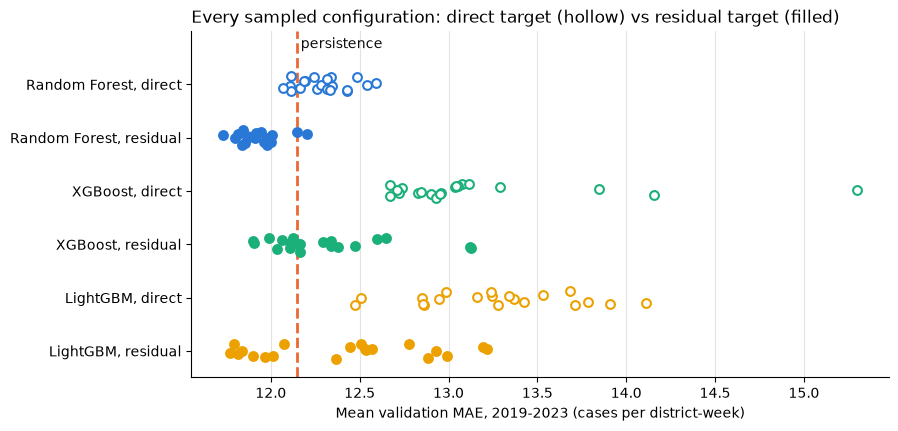

target,direct: configs beating persistence,residual: configs beating persistence
algorithm,,
Random Forest,4,18
XGBoost,0,8
LightGBM,0,8


In [18]:
tuning_all = pd.concat([tuning_level, tuning_change], ignore_index=True)
rows = [(name, target) for name in ALGORITHMS for target in ["level", "change"]]
labels = [f"{name}, {'direct' if target == 'level' else 'residual'}" for name, target in rows]

fig, ax = plt.subplots(figsize=(9, 4.5))
for pos, (name, target) in enumerate(rows):
    maes = tuning_all.query("algorithm == @name and target == @target")["MAE"]
    jitter = np.random.default_rng(pos).uniform(-0.15, 0.15, len(maes))
    filled = target == "change"
    ax.scatter(maes, pos + jitter, s=40, color=ALGO_COLORS[name] if filled else "white",
               edgecolor=ALGO_COLORS[name], linewidth=1.5, zorder=3)
ax.axvline(persistence_by_year["MAE"].mean(), color=COLORS["Persistence"], linestyle="--", linewidth=2)
ax.set_yticks(range(len(rows)), labels)
ax.set_ylim(len(rows) - 0.5, -1.0)  # inverted: first row on top, room for the label
ax.text(persistence_by_year["MAE"].mean(), -0.75, " persistence", color=INK, va="center")
ax.set_xlabel("Mean validation MAE, 2019-2023 (cases per district-week)")
ax.set_title("Every sampled configuration: direct target (hollow) vs residual target (filled)", loc="left")
style(ax, "x")
plt.show()

(tuning_all.assign(beats_persistence=tuning_all["MAE"] < persistence_by_year["MAE"].mean())
 .pivot_table(index="algorithm", columns="target", values="beats_persistence", aggfunc="sum")
 .loc[list(ALGORITHMS), ["level", "change"]]
 .rename(columns={"level": "direct: configs beating persistence", "change": "residual: configs beating persistence"}))

**Residual prediction helps every algorithm**

| Algorithm | Direct MAE | Residual MAE | Residual vs persistence |
|---|---|---|---|
| Random Forest | 12.07 | **11.73** | -3.4% |
| XGBoost | 12.67 | 11.90 | -2.0% |
| LightGBM | 12.48 | 11.77 | -3.1% |

- With the change target, all three tuned models beat persistence on **MAE, RMSE and high-incidence-week MAE** (30.2-30.8 vs 31.3).
- It is not one lucky configuration. 18 of the 20 Random Forest configurations beat persistence with the residual target (4 of 20 with the direct target). XGBoost and LightGBM go from 0 to 8 of 20.
- The best residual configurations are again the **most conservative** ones offered: Random Forest with `min_samples_leaf=20` (the largest value in the grid), LightGBM with 7 leaves, 200 trees and learning rate 0.01, and XGBoost with depth-2 trees and learning rate 0.01. These models make small, cautious corrections to persistence. Several best values sit **at the edge of the search ranges**, so a follow-up search that extends the ranges in that direction could improve them further.

In [19]:
selection_check(tuning_change).round(2)

,config picked on 2019-21,its MAE 2022-23,config picked on 2019-23,its MAE 2022-23,persistence MAE 2022-23
algorithm,,,,,
Random Forest,4,14.31,4,14.31,14.95
XGBoost,12,14.53,16,14.37,14.95
LightGBM,10,14.38,10,14.38,14.95


The same check for the residual target: Random Forest and LightGBM again pick the same configuration from 2019-2021 alone. All three still beat persistence on 2022-2023 (14.3-14.5 vs 14.95).

## 10. Experiment B: weighted ensemble

Combine the strongest models with weights that sum to 1:

$$\hat y = w_1 \hat y_{\text{RF}} + w_2 \hat y_{\text{XGBoost}} + w_3 \hat y_{\text{LightGBM}}$$

**Components:** for each algorithm, its best tuned configuration with whichever target (direct or residual) scored better.

**Choosing the weights fairly.** If the weights were chosen to minimise MAE on 2019-2023 and then scored on 2019-2023, the result would be too optimistic. So the weights are chosen **forward in time**, like the folds:

| Weights chosen on validation years | Blend scored on |
|---|---|
| 2019 | 2020 |
| 2019-2020 | 2021 |
| 2019-2021 | 2022 |
| 2019-2022 | 2023 |

This gives an honest blend score for 2020-2023 (2019 cannot be scored, since there are no earlier predictions to choose weights from). The weights are searched on a grid in steps of 0.05, and the objective is the mean yearly MAE. The weights saved for the final model are chosen on all five years.

In [20]:
better_target = {
    name: "change" if best_change.loc[name, "MAE"] <= best_level.loc[name, "MAE"] else "level"
    for name in ALGORITHMS
}
components = {}
for name, target in better_target.items():
    best = (best_change if target == "change" else best_level).loc[name]
    components[name] = {"target": target, "config": int(best["config"]), "params": best["params"]}

component_preds = pd.DataFrame({
    name: (preds_change if c["target"] == "change" else preds_level)[(name, c["target"], c["config"])]
    for name, c in components.items()
})

pd.DataFrame(components).T[["target", "config", "params"]]

,target,config,params
Random Forest,change,4,"{'n_estimators': 100, 'min_samples_leaf': 20, 'max_features': 0.7, 'max_depth': 10}"
XGBoost,change,16,"{'subsample': 0.8, 'n_estimators': 400, 'max_depth': 2, 'learning_rate': 0.01, 'colsample_bytree': 1.0}"
LightGBM,change,10,"{'num_leaves': 7, 'n_estimators': 200, 'min_child_samples': 100, 'max_depth': 10, 'learning_rate': 0.01}"


How different are the three components? A blend can only cancel errors if the models make *different* errors. Correlation of their prediction errors on the validation weeks:

In [21]:
component_errors = component_preds.sub(train.loc[component_preds.index, "cases_next"], axis=0)
component_errors.corr().round(3)

,Random Forest,XGBoost,LightGBM
Random Forest,1.000,0.978,0.988
XGBoost,0.978,1.000,0.980
LightGBM,0.988,0.980,1.000


In [22]:
STEP = 0.05
grid_steps = round(1 / STEP)
WEIGHT_GRID = [
    np.array([a, b, grid_steps - a - b]) / grid_steps
    for a, b in product(range(grid_steps + 1), repeat=2) if a + b <= grid_steps
]

def blend(weights, rows=slice(None)):
    return component_preds.loc[rows] @ np.asarray(weights)

def yearly_mae(pred, years):
    return np.mean([
        mean_absolute_error(train.loc[valid_rows, "cases_next"], pred.loc[train.index[valid_rows]])
        for year, _, valid_rows in folds if year in years
    ])

def fit_weights(years):
    return min(WEIGHT_GRID, key=lambda w: yearly_mae(blend(w), years))

# forward-chained: weights for year Y use only validation years before Y
forward_weights, forward_preds = {}, []
for year, _, valid_rows in folds[1:]:
    w = fit_weights([y for y in VALIDATION_YEARS if y < year])
    forward_weights[year] = w
    forward_preds.append(blend(w, train.index[valid_rows]))
forward_blend = pd.concat(forward_preds)

final_weights = fit_weights(VALIDATION_YEARS)

weights_table = pd.DataFrame(forward_weights, index=list(components)).T
weights_table.index = [f"chosen on 2019-{y - 1}, used for {y}" for y in weights_table.index]
weights_table.loc["final: chosen on 2019-2023"] = final_weights
weights_table.round(2)

,Random Forest,XGBoost,LightGBM
"chosen on 2019-2019, used for 2020",0.95,0.05,0.00
"chosen on 2019-2020, used for 2021",0.60,0.00,0.40
"chosen on 2019-2021, used for 2022",0.60,0.00,0.40
"chosen on 2019-2022, used for 2023",0.80,0.00,0.20
final: chosen on 2019-2023,0.65,0.10,0.25


Fair comparison on **2020-2023** (the years the forward-chained blend can be scored on):

In [23]:
BLEND_YEARS = [2020, 2021, 2022, 2023]

def mean_over(by_year, years):
    return by_year.loc[years].mean()

blend_compare = {"Persistence": mean_over(persistence_by_year, BLEND_YEARS)}
for name, c in components.items():
    label = f"{name} ({'residual' if c['target'] == 'change' else 'direct'})"
    blend_compare[label] = mean_over(evaluate(component_preds[name]), BLEND_YEARS)
blend_compare["Weighted ensemble (forward-chained)"] = evaluate(forward_blend).mean()

blend_compare = pd.DataFrame(blend_compare).T
blend_compare["MAE vs persistence (%)"] = 100 * (blend_compare["MAE"] / blend_compare.loc["Persistence", "MAE"] - 1)
blend_compare.round(2)

,MAE,RMSE,high-week MAE,high-week bias,MAE vs persistence (%)
Persistence,11.01,24.99,30.38,-9.69,0.00
Random Forest (residual),10.70,23.74,29.25,-11.65,-2.79
XGBoost (residual),10.76,24.01,29.54,-10.42,-2.23
LightGBM (residual),10.70,23.95,29.07,-10.76,-2.84
Weighted ensemble (forward-chained),10.70,23.82,29.19,-11.44,-2.77


**The weighted ensemble adds nothing measurable.**

- The three residual models' errors are **0.98-0.99 correlated**: they make almost the same mistakes, so averaging them cancels very little.
- The forward-chained weights favour the Random Forest (0.60-0.95) but change from year to year. The forward-chained blend scores MAE **10.70** on 2020-2023, the same as the best single models (RF and LightGBM residual: 10.70), with a slightly higher RMSE (23.82 vs 23.74).
- Even with weights chosen on all five years (the optimistic version), MAE only moves from 11.73 to 11.72.

A blend of near-identical models costs three models to train and maintain for no gain, so a single model is preferred (section 12).

## 11. Model comparison

All candidates side by side. *Validation MAE / RMSE* is the mean over 2019-2023. The weighted ensemble appears twice:
- with the final weights (chosen on 2019-2023), so it can be compared on all five years, but **optimistically**;
- forward-chained (honest), which only exists for 2020-2023.

The last two columns compare every model on 2020-2023, where the honest blend can also be scored.

In [24]:
best_residual_name = best_change["MAE"].idxmin()
final_blend = blend(final_weights)

CANDIDATES = {
    "Persistence": (persistence_pred, "None"),
    "Tuned Random Forest": (preds_level[("Random Forest", "level", int(best_level.loc["Random Forest", "config"]))],
                            best_level.loc["Random Forest", "params"]),
    "Tuned XGBoost": (preds_level[("XGBoost", "level", int(best_level.loc["XGBoost", "config"]))],
                      best_level.loc["XGBoost", "params"]),
    "Tuned LightGBM": (preds_level[("LightGBM", "level", int(best_level.loc["LightGBM", "config"]))],
                       best_level.loc["LightGBM", "params"]),
    "Residual-based model": (preds_change[(best_residual_name, "change", int(best_change.loc[best_residual_name, "config"]))],
                             {"algorithm": best_residual_name, **best_change.loc[best_residual_name, "params"]}),
    "Weighted ensemble (final weights, optimistic)": (final_blend,
                                                      dict(zip(components, np.round(final_weights, 2)))),
    "Weighted ensemble (forward-chained)": (forward_blend, "weights re-chosen each year"),
}

by_year_all = {name: evaluate(pred) for name, (pred, _) in CANDIDATES.items()}

comparison = pd.DataFrame({
    name: {
        "Validation MAE": by_year["MAE"].mean() if len(by_year) == 5 else np.nan,
        "Validation RMSE": by_year["RMSE"].mean() if len(by_year) == 5 else np.nan,
        "High-week MAE": by_year["high-week MAE"].mean() if len(by_year) == 5 else np.nan,
        "High-week bias": by_year["high-week bias"].mean() if len(by_year) == 5 else np.nan,
        "MAE 2020-23": mean_over(by_year, BLEND_YEARS)["MAE"],
        "RMSE 2020-23": mean_over(by_year, BLEND_YEARS)["RMSE"],
    }
    for name, by_year in by_year_all.items()
}).T
comparison.round(2)

,Validation MAE,Validation RMSE,High-week MAE,High-week bias,MAE 2020-23,RMSE 2020-23
Persistence,12.15,26.87,31.33,-9.09,11.01,24.99
Tuned Random Forest,12.07,26.19,31.49,-13.30,10.97,24.02
Tuned XGBoost,12.67,27.67,32.94,-14.50,11.27,24.31
Tuned LightGBM,12.48,27.71,32.57,-16.11,11.00,24.14
Residual-based model,11.73,25.61,30.28,-12.65,10.70,23.74
"Weighted ensemble (final weights, optimistic)",11.72,25.65,30.20,-12.31,10.68,23.75
Weighted ensemble (forward-chained),NaN,NaN,NaN,NaN,10.70,23.82


In [25]:
pd.DataFrame({"Best parameters": {name: params for name, (_, params) in CANDIDATES.items()}})

,Best parameters
Persistence,None
Tuned Random Forest,"{'n_estimators': 200, 'min_samples_leaf': 10, 'max_features': 0.7, 'max_depth': 10}"
Tuned XGBoost,"{'subsample': 0.8, 'n_estimators': 800, 'max_depth': 2, 'learning_rate': 0.01, 'colsample_bytree': 0.8}"
Tuned LightGBM,"{'num_leaves': 15, 'n_estimators': 200, 'min_child_samples': 20, 'max_depth': 5, 'learning_rate': 0.05}"
Residual-based model,"{'algorithm': 'Random Forest', 'n_estimators': 100, 'min_samples_leaf': 20, 'max_features': 0.7, 'max_depth': 10}"
"Weighted ensemble (final weights, optimistic)","{'Random Forest': 0.65, 'XGBoost': 0.1, 'LightGBM': 0.25}"
Weighted ensemble (forward-chained),weights re-chosen each year


### Per-year comparison

Validation MAE in each year. The forward-chained blend has no 2019 value.

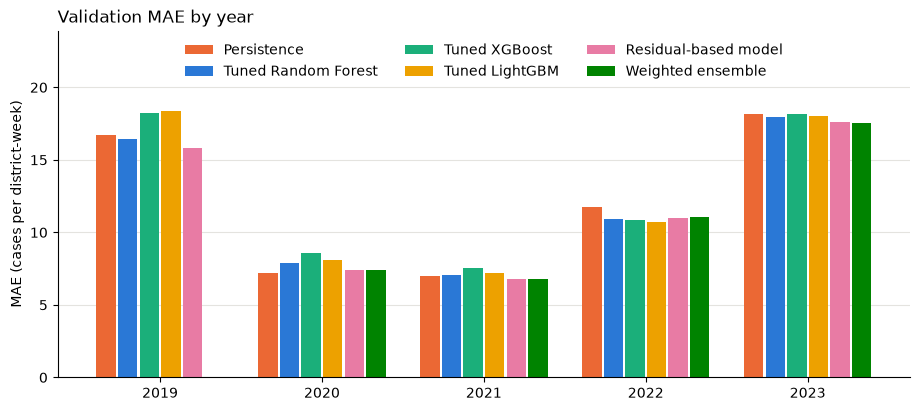

,Persistence,Tuned Random Forest,Tuned XGBoost,Tuned LightGBM,Residual-based model,Weighted ensemble (forward-chained)
year,,,,,,
2019,16.69,16.45,18.26,18.38,15.85,NaN
2020,7.17,7.92,8.56,8.09,7.41,7.41
2021,6.97,7.07,7.53,7.18,6.78,6.77
2022,11.72,10.95,10.86,10.73,11.01,11.07
2023,18.17,17.95,18.13,18.00,17.62,17.57


In [26]:
CHART_MODELS = ["Persistence", "Tuned Random Forest", "Tuned XGBoost", "Tuned LightGBM",
                "Residual-based model", "Weighted ensemble (forward-chained)"]

def chart_color(name):
    return COLORS["Weighted ensemble"] if name.startswith("Weighted") else COLORS[name]

yearly = pd.DataFrame({name: by_year_all[name]["MAE"] for name in CHART_MODELS}).reindex(VALIDATION_YEARS)

fig, ax = plt.subplots(figsize=(11, 4.5))
width = 0.8 / len(CHART_MODELS)
x = np.arange(len(VALIDATION_YEARS))
for k, name in enumerate(CHART_MODELS):
    ax.bar(x + (k - (len(CHART_MODELS) - 1) / 2) * width, yearly[name], width * 0.9,
           color=chart_color(name), label=name.replace(" (forward-chained)", ""))
ax.set_xticks(x, VALIDATION_YEARS)
ax.set_ylabel("MAE (cases per district-week)")
ax.set_title("Validation MAE by year", loc="left")
style(ax)
ax.legend(frameon=False, ncol=3, loc="upper center")
ax.set_ylim(0, yearly.max().max() * 1.3)
plt.show()

yearly.round(2)

Because the yearly error levels are so different, the same comparison is clearer as the **% change from persistence** in each year (below zero = better than persistence), for all weeks and for high-incidence weeks:

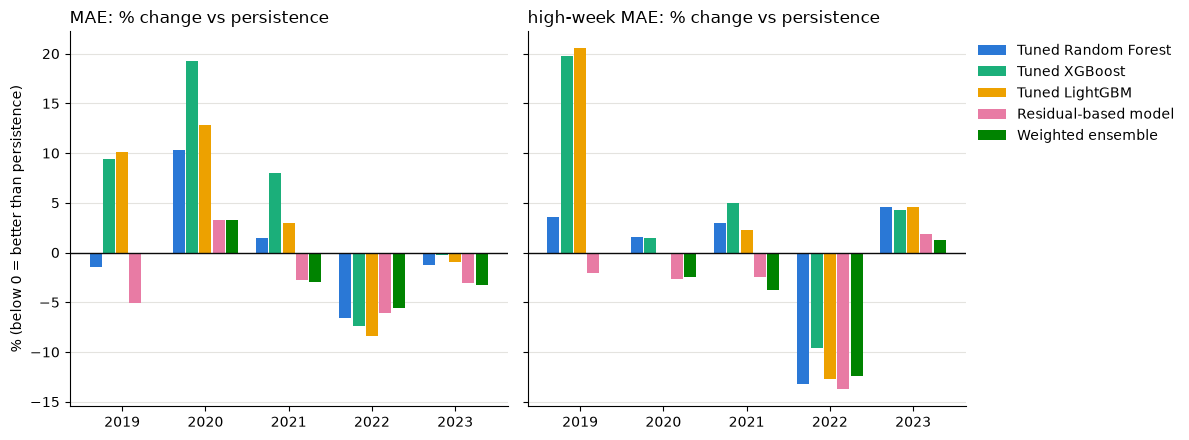

MAE                                                    \
     Tuned Random Forest Tuned XGBoost Tuned LightGBM Residual-based model   
year                                                                         
2019                -1.4           9.4           10.1                 -5.1   
2020                10.3          19.3           12.8                  3.3   
2021                 1.4           8.0            3.0                 -2.8   
2022                -6.6          -7.4           -8.4                 -6.1   
2023                -1.2          -0.2           -0.9                 -3.0   

                                               high-week MAE                \
     Weighted ensemble (forward-chained) Tuned Random Forest Tuned XGBoost   
year                                                                         
2019                                 NaN                 3.5          19.8   
2020                                 3.3                 1.6           1.4   
2021                                -2.9                 3.0           5.0   
2022                                -5.6               -13.2          -9.6   
2023                                -3.3                 4.6           4.3   

                                                                              
     Tuned LightGBM Residual-based model Weighted ensemble (forward-chained)  
year                                                                          
2019           20.5                 -2.1                                 NaN  
2020           -0.1                 -2.7                                -2.5  
2021            2.2                 -2.5                                -3.7  
2022          -12.7                -13.8                               -12.4  
2023            4.5                  1.9                                 1.3

In [27]:
MODELS_ONLY = CHART_MODELS[1:]
pct = {
    metric: pd.DataFrame({
        name: 100 * (by_year_all[name][metric] / persistence_by_year[metric] - 1) for name in MODELS_ONLY
    }).reindex(VALIDATION_YEARS)
    for metric in ["MAE", "high-week MAE"]
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
width = 0.8 / len(MODELS_ONLY)
for ax, (metric, table) in zip(axes, pct.items()):
    for k, name in enumerate(MODELS_ONLY):
        ax.bar(x + (k - (len(MODELS_ONLY) - 1) / 2) * width, table[name], width * 0.9,
               color=chart_color(name), label=name.replace(" (forward-chained)", ""))
    ax.axhline(0, color=INK, linewidth=1)
    ax.set_xticks(x, VALIDATION_YEARS)
    ax.set_title(f"{metric}: % change vs persistence", loc="left")
    style(ax)
axes[0].set_ylabel("% (below 0 = better than persistence)")
axes[1].legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
plt.show()

pd.concat(pct, axis=1).round(1)

**What the yearly view shows**

- **No model beats persistence in every year.** The residual model is better in 2019, 2021, 2022 and 2023 (-2.8% to -6.1%) and worse in **2020** (+3.3%). Every model is worse than persistence in 2020. That year had unusually low dengue activity and was also the first COVID-19 year, so the season may not have followed the usual pattern the models learned. This is a possible explanation, not something tested here.
- The **direct-target boosters** are the least stable: +9-10% MAE in 2019 and +13-19% in 2020, with about +20% in 2019's high-incidence weeks.
- In **high-incidence weeks** the residual model is better than persistence in 2019-2022 but slightly worse in the 2023 outbreak (+1.9%). The gains during outbreaks are small: -3.4% over the five-year mean.

## 12. Selecting the model

**Rule:** the model with the lowest MAE on 2020-2023 (the years where every candidate, including the honest forward-chained blend, has a score), as long as it beats persistence. If the weighted ensemble is not better than its best single component, the single model is preferred because it is simpler.

In [28]:
SELECTABLE = ["Tuned Random Forest", "Tuned XGBoost", "Tuned LightGBM",
              "Residual-based model", "Weighted ensemble (forward-chained)"]
selected_name = comparison.loc[SELECTABLE, "MAE 2020-23"].idxmin()
assert comparison.loc[selected_name, "MAE 2020-23"] < comparison.loc["Persistence", "MAE 2020-23"]

if selected_name.startswith("Weighted"):
    selected_components = [
        {"algorithm": name, **components[name], "weight": float(w)}
        for name, w in zip(components, final_weights) if w > 0
    ]
    selected_pred = forward_blend
else:
    pred, params = CANDIDATES[selected_name]
    if selected_name == "Residual-based model":
        algo, target = best_residual_name, "change"
        config = int(best_change.loc[algo, "config"])
    else:
        algo, target = selected_name.replace("Tuned ", ""), "level"
        config = int(best_level.loc[algo, "config"])
    selected_components = [{"algorithm": algo, "target": target, "config": config,
                            "params": CONFIGS[algo][config], "weight": 1.0}]
    selected_pred = pred

print("selected:", selected_name)
pd.DataFrame(selected_components)

selected: Residual-based model


,algorithm,target,config,params,weight
0,Random Forest,change,4,"{'n_estimators': 100, 'min_samples_leaf': 20, 'max_features': 0.7, 'max_depth': 10}",1.0


### Errors by district

MAE of the selected model and of persistence in each district, pooled over the validation weeks the selected model was scored on. Districts are sorted by persistence MAE, which mostly reflects how many cases the district has.

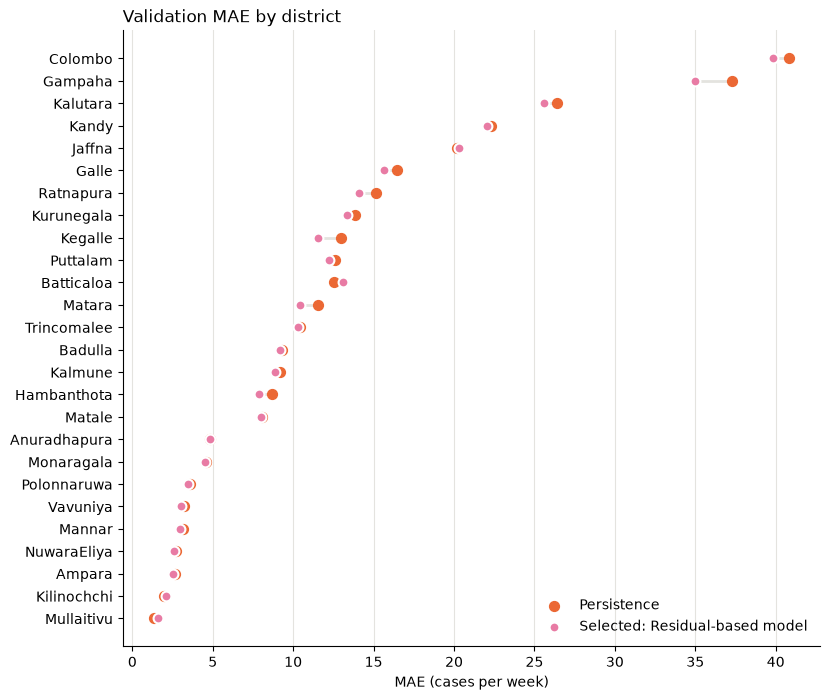

,Persistence,Selected model,mean weekly cases,change vs persistence (%)
district,,,,
Mullaitivu,1.37,1.58,1.72,15.02
Kilinochchi,1.99,2.09,3.44,4.68
Batticaloa,12.56,13.07,52.17,4.09
Jaffna,20.16,20.31,71.13,0.74
Anuradhapura,4.82,4.80,10.79,-0.46
Matale,8.07,8.01,24.38,-0.77
Trincomalee,10.40,10.29,31.20,-1.06
Badulla,9.28,9.18,24.18,-1.09
Monaragala,4.57,4.52,7.72,-1.13


In [29]:
scored = train.loc[selected_pred.index]
district_mae = pd.DataFrame({
    "Persistence": (scored["current_week_cases"] - scored["cases_next"]).abs().groupby(scored["district"]).mean(),
    "Selected model": (selected_pred - scored["cases_next"]).abs().groupby(scored["district"]).mean(),
    "mean weekly cases": scored.groupby("district")["cases_next"].mean(),
}).sort_values("Persistence")
district_mae["change vs persistence (%)"] = 100 * (district_mae["Selected model"] / district_mae["Persistence"] - 1)

fig, ax = plt.subplots(figsize=(9, 8))
y = np.arange(len(district_mae))
ax.hlines(y, district_mae[["Persistence", "Selected model"]].min(axis=1),
          district_mae[["Persistence", "Selected model"]].max(axis=1), color=GRID, linewidth=2)
ax.scatter(district_mae["Persistence"], y, s=50, color=COLORS["Persistence"], label="Persistence", zorder=3)
selected_color = chart_color(selected_name)
ax.scatter(district_mae["Selected model"], y, s=50, color=selected_color, edgecolor="white",
           linewidth=1.5, label=f"Selected: {selected_name.replace(' (forward-chained)', '')}", zorder=4)
ax.set_yticks(y, district_mae.index)
ax.set_xlabel("MAE (cases per week)")
ax.set_title("Validation MAE by district", loc="left")
style(ax, "x")
ax.legend(frameon=False, loc="lower right")
plt.show()

district_mae.sort_values("change vs persistence (%)", ascending=False).round(2)

**By district:** the selected model has a lower MAE than persistence in **22 of 26 districts**. The biggest gains are in Kegalle (-11%), Matara, Hambanthota, Ratnapura and Gampaha (-6% to -10%). Gampaha also has one of the largest absolute errors (37.3 → 35.0 cases).

It is worse in **Mullaitivu (+15%, but only 1.4 → 1.6 cases), Kilinochchi, Batticaloa (+4%) and Jaffna (+1%)**, all in the north and east. These districts' dengue season is linked to the north-east monsoon, so it is timed differently from the western and southern districts that dominate the training data. With one shared model and only `district_code` to tell districts apart, the learned corrections fit them less well. Per-region features or models could address this later.

### A closer look: Colombo in 2023

The same view as notebook 04: actual weekly cases next to persistence and the selected model, for the district with the most cases, in the last validation year (an outbreak year).

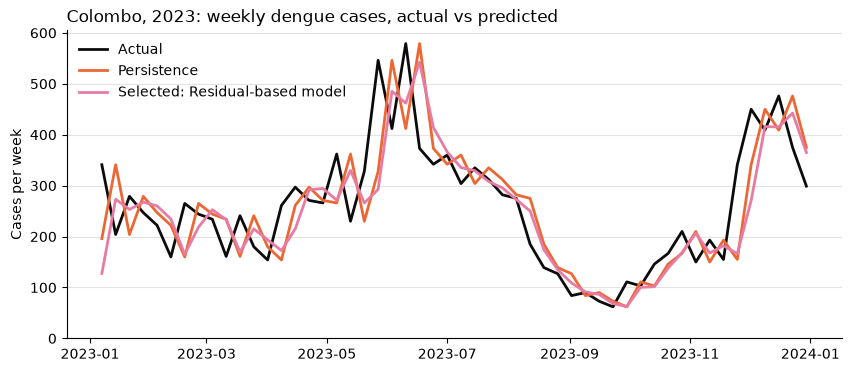

persistence MAE       65.06
selected model MAE    57.85
dtype: float64

In [30]:
scored = train.loc[selected_pred.index].assign(pred=selected_pred)
colombo = (scored[(scored["district"] == "Colombo") & (scored["target_date"].dt.year == 2023)]
           .set_index("target_date").sort_index())

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(colombo.index, colombo["cases_next"], color=INK, linewidth=2, label="Actual")
ax.plot(colombo.index, colombo["current_week_cases"], color=COLORS["Persistence"], linewidth=2, label="Persistence")
ax.plot(colombo.index, colombo["pred"], color=selected_color, linewidth=2,
        label=f"Selected: {selected_name.replace(' (forward-chained)', '')}")
ax.set_title("Colombo, 2023: weekly dengue cases, actual vs predicted", loc="left")
ax.set_ylabel("Cases per week")
ax.set_ylim(bottom=0)
style(ax)
ax.legend(frameon=False)
plt.show()

pd.Series({
    "persistence MAE": (colombo["current_week_cases"] - colombo["cases_next"]).abs().mean(),
    "selected model MAE": (colombo["pred"] - colombo["cases_next"]).abs().mean(),
}).round(2)

In Colombo 2023 the selected model's MAE is 57.9 vs 65.1 for persistence (-11%). It still **lags the actual curve by about a week**, like persistence, and it does not anticipate the June or December rises. Its gain comes from being **smoother**: it does not copy the large week-to-week zigzags (e.g. May-July) that make persistence's errors double up.

## 13. Save the tuning record and selected configuration

Two files are written to `models/`. No fitted model is saved: for the final evaluation, the selected configuration is retrained once on all of `train.csv` (target weeks 2007-2023) and scored once on `test.csv`.

- `05_regression_tuning_results.csv`: every sampled configuration, both targets, with its validation scores.
- `05_selected_regression_config.json`: the selected model (algorithms, targets, hyperparameters, weights), the best configuration of every algorithm, and the validation scores to compare against later.

In [31]:
def to_builtin(value):
    # make numpy numbers and NaN JSON-friendly
    if isinstance(value, dict):
        return {k: to_builtin(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [to_builtin(v) for v in value]
    if isinstance(value, np.generic):
        value = value.item()
    if isinstance(value, float) and np.isnan(value):
        return None
    return value

MODELS_DIR.mkdir(exist_ok=True)
(tuning_all.assign(params=tuning_all["params"].map(json.dumps))
 .round(4).to_csv(TUNING_PATH, index=False))

config = {
    "created_by": "notebooks analysis/05_ensemble_model_training.ipynb",
    "task": "regression: next week's dengue cases per district (cases_next)",
    "features": FEATURES,
    "prediction": "clip(prediction, 0); for target 'change': current_week_cases + predicted change",
    "validation": {
        "scheme": "expanding window, 5 folds",
        "validation_years": VALIDATION_YEARS,
        "excluded_from_scoring": "target_imputed rows",
        "configs_per_algorithm": N_CONFIGS,
        "random_state": RANDOM_STATE,
    },
    "selected_model": {
        "name": selected_name,
        "components": selected_components,
        "validation_mae_2020_2023": comparison.loc[selected_name, "MAE 2020-23"],
        "validation_rmse_2020_2023": comparison.loc[selected_name, "RMSE 2020-23"],
    },
    "best_configs": {
        f"{name} ({'direct' if target == 'level' else 'residual'})": {
            "target": target,
            "params": table.loc[name, "params"],
            "validation_mae": table.loc[name, "MAE"],
            "validation_rmse": table.loc[name, "RMSE"],
            "high_week_mae": table.loc[name, "high-week MAE"],
        }
        for target, table in [("level", best_level), ("change", best_change)] for name in ALGORITHMS
    },
    "ensemble_weights_final": dict(zip(components, final_weights)),
    "comparison": comparison.to_dict(orient="index"),
}
CONFIG_PATH.write_text(json.dumps(to_builtin(config), indent=2))

print("saved", TUNING_PATH.name, tuning_all.shape, "|", CONFIG_PATH.name)

saved 05_regression_tuning_results.csv (120, 13) | 05_selected_regression_config.json


## 14. Summary

**Model comparison** (expanding-window validation; the test set was not used)

| Model | Validation MAE (2019-23) | Validation RMSE (2019-23) | High-week MAE | MAE 2020-23 | Best parameters |
|---|---|---|---|---|---|
| Persistence | 12.15 | 26.87 | 31.33 | 11.01 | None |
| Tuned Random Forest | 12.07 | 26.19 | 31.49 | 10.97 | `n_estimators=200, max_depth=10, min_samples_leaf=10, max_features=0.7` |
| Tuned XGBoost | 12.67 | 27.67 | 32.94 | 11.27 | `n_estimators=800, max_depth=2, learning_rate=0.01, subsample=0.8, colsample_bytree=0.8` |
| Tuned LightGBM | 12.48 | 27.71 | 32.57 | 11.00 | `n_estimators=200, num_leaves=15, max_depth=5, learning_rate=0.05, min_child_samples=20` |
| **Residual-based model (RF)** | **11.73** | **25.61** | 30.28 | **10.70** | `n_estimators=100, max_depth=10, min_samples_leaf=20, max_features=0.7` |
| Weighted ensemble (residual RF / XGB / LGBM) | 11.72 *(optimistic)* | 25.65 *(optimistic)* | 30.20 *(optimistic)* | 10.70 *(forward-chained)* | weights 0.65 / 0.10 / 0.25 |

**Selected for final evaluation: residual Random Forest.** It predicts the weekly change and adds it to the current week's cases. Its configuration is saved in `models/05_selected_regression_config.json`.

**Key findings**
1. Tuning toward **more conservative trees** (larger leaves, shallower depth, slower learning) is what helps on this data. Default, deep models fit noise.
2. **Residual prediction is the main improvement.** It builds persistence into the model, and all three algorithms beat the baseline once it is used. On the direct target, only the Random Forest barely does.
3. The **weighted ensemble gives no benefit**, because the three residual models make almost identical errors.
4. The improvement over persistence is **real but modest**: about 3.4% lower MAE, 4.7% lower RMSE and 3.4% lower high-incidence-week MAE. It is not uniform: worse than persistence in 2020 and in four northern/eastern districts.
5. **Outbreaks are still underestimated.** In high-incidence weeks, every model's average error is negative (residual RF: about -12.6 cases), and slightly more negative than persistence's (-9.1). The model reduces large overshoots after peaks, but it does not anticipate rising outbreaks.

**Limitations**
- The configurations were chosen using the same five validation years they are scored on. Section 8 shows the choice holds up on unseen years, but the scores are still slightly optimistic. The test set will give the unbiased number.
- Several best hyperparameters sit at the edge of the suggested ranges.

**Next steps**
1. *(Optional)* A second, narrower search that extends the conservative end of the ranges (e.g. `min_samples_leaf` 30-100, LightGBM `min_child_samples` > 100, learning rates below 0.01).
2. **Risk classification (`risk_next`)** as a separate stage with macro F1, confusion matrices and high-risk recall. A useful extra baseline there: convert this notebook's predicted counts into risk levels with `03_risk_thresholds.csv`.
3. **Final evaluation:** retrain the selected configuration on all of `train.csv` (target weeks 2007-2023) and score it once on `test.csv` (2024-2026), next to persistence. Keep in mind the test period's larger outbreaks and the possibly under-reported last 2026 weeks (notebooks 02 and 03).